### Import the necessary libraries

In [33]:
import os
import torch
import kagglehub
import numpy as np
import pandas as pd
from torch import nn
import seaborn as sns
from PIL import ImageFile
from tqdm.auto import tqdm
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.metrics import confusion_matrix, roc_curve, auc

### Download latest version of the dataset from Kaggle

In [34]:
path = kagglehub.dataset_download("abdelghaniaaba/wildfire-prediction-dataset")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\keert\.cache\kagglehub\datasets\abdelghaniaaba\wildfire-prediction-dataset\versions\1


### Load the dataset using ImageFolder and apply transformations

In [35]:
ImageFile.LOAD_TRUNCATED_IMAGES = True

train_dataset = ImageFolder(os.path.join(path, "train"), transform=transforms.ToTensor())
test_dataset = ImageFolder(os.path.join(path, "test"), transform=transforms.ToTensor())
valid_dataset = ImageFolder(os.path.join(path, "valid"), transform=transforms.ToTensor())

### Inspecting the data

Number of training samples: 30250
Number of test samples: 6300
Number of validation samples: 6300
Number of classes: 2
Class names: ['nowildfire', 'wildfire']
Class to index mapping: {'nowildfire': 0, 'wildfire': 1}
Image shape: torch.Size([3, 350, 350])


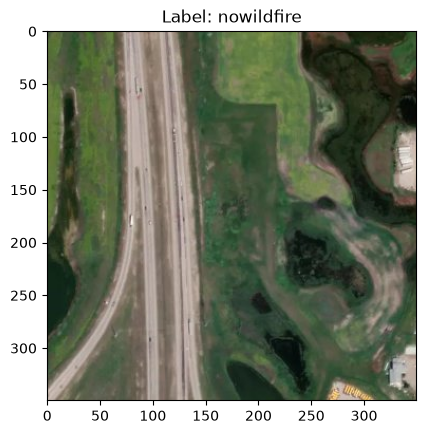

In [36]:
# Get attributes of the datasets
print("Number of training samples:", len(train_dataset))
print("Number of test samples:", len(test_dataset))
print("Number of validation samples:", len(valid_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Class names:", train_dataset.classes)
print("Class to index mapping:", train_dataset.class_to_idx)
print("Image shape:", train_dataset[0][0].shape)

img, label = train_dataset[0]
plt.imshow(img.permute(1, 2, 0))
plt.title(f"Label: {train_dataset.classes[label]}")
plt.show()

### Create the dataloaders

In [37]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)
valid_dataloader = DataLoader(valid_dataset, batch_size=32, shuffle=False)

### Create the model

In [38]:
# Check if GPU is available and set the device accordingly
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load the pre-trained ResNet18 model
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Replace the classification head for binary output
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)

model = model.to(device)

print("Model architecture:")
print(model)

Device: cuda
Model architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

### Define the loss function and optimizer

In [39]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

### Training function

In [40]:
def plot_learning_curves(history, num_epochs):
    """Plots loss and accuracy side-by-side for training and validation."""
    epochs = range(1, num_epochs + 1)
    
    plt.figure(figsize=(14, 5))

    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss", marker="o")
    plt.plot(epochs, history["valid_loss"], label="Validation Loss", marker="o")
    plt.title("Training & Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.grid(True)
    plt.legend()

    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Accuracy", marker="o")
    plt.plot(epochs, history["valid_acc"], label="Validation Accuracy", marker="o")
    plt.title("Training & Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

In [41]:
def train_model(model, criterion, optimizer, train_loader, valid_loader, num_epochs=10):
    history = {
        "train_loss": [],
        "train_acc": [],
        "valid_loss": [],
        "valid_acc": []
    }

    for epoch in range(num_epochs):
        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        
        train_progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [Train]")
        for inputs, labels in train_progress:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            predicted = torch.argmax(outputs, dim=1)
            correct_train += (predicted == labels).sum().item()
            total_train += labels.size(0)
            
            train_progress.set_postfix(
                loss=f"{running_loss / total_train:.4f}", 
                accuracy=f"{correct_train / total_train:.4f}"
            )

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct_train / total_train
        
        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")

        # --- Validation Phase ---
        model.eval()
        valid_loss = 0.0
        correct_valid = 0
        total_valid = 0
        
        with torch.no_grad():
            valid_progress = tqdm(valid_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [Valid]")
            for inputs, labels in valid_progress:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                valid_loss += loss.item() * inputs.size(0)
                predicted = torch.argmax(outputs, dim=1)
                total_valid += labels.size(0)
                correct_valid += (predicted == labels).sum().item()
                
                valid_progress.set_postfix(
                    loss=f"{valid_loss / total_valid:.4f}", 
                    accuracy=f"{correct_valid / total_valid:.4f}"
                )

        epoch_valid_loss = valid_loss / len(valid_loader.dataset)
        epoch_valid_acc = correct_valid / total_valid if total_valid > 0 else 0
        
        history["valid_loss"].append(epoch_valid_loss)
        history["valid_acc"].append(epoch_valid_acc)

        print(f"Validation Loss: {epoch_valid_loss:.4f} | Validation Acc: {epoch_valid_acc:.4f}\n")

        torch.save(model.state_dict(), "satellite_image_classification_model.pth")

    # Plot training vs validation curves after all epochs
    plot_learning_curves(history, num_epochs)
    return history

### Test the model

In [42]:
def plot_test_results(y_true, y_pred, y_probs, class_names=None):
    """Plots Confusion Matrix and ROC Curve for test set evaluation."""
    if class_names is None:
        class_names = ["Class 0", "Class 1"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # 1. Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title("Test Confusion Matrix")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    # 2. ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.3f})")
    axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_ylim([0.0, 1.05])
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title("Test Receiver Operating Characteristic (ROC)")
    axes[1].legend(loc="lower right")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

In [43]:
def test_model(model, test_loader, class_names=None):
    """Evaluates test accuracy and plots Confusion Matrix & ROC Curve."""
    model.eval()
    correct = 0
    total = 0
    
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, desc="Testing"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            
            # Apply Softmax to obtain probabilities for class 1
            probs = torch.softmax(outputs, dim=1)[:, 1]
            predicted = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    test_acc = correct / total
    print(f"\nFinal Test Accuracy: {test_acc:.4f}\n")

    # Plot Confusion Matrix & ROC Curve
    plot_test_results(all_labels, all_preds, all_probs, class_names)

### Run the model

Epoch 1/10 [Train]: 100%|██████████| 946/946 [07:25<00:00,  2.12it/s, accuracy=0.9775, loss=0.0608]


Epoch 1/10 | Train Loss: 0.0608 | Train Acc: 0.9775


Epoch 1/10 [Valid]: 100%|██████████| 197/197 [01:10<00:00,  2.78it/s, accuracy=0.9822, loss=0.0515]


Validation Loss: 0.0515 | Validation Acc: 0.9822



Epoch 2/10 [Train]: 100%|██████████| 946/946 [07:39<00:00,  2.06it/s, accuracy=0.9908, loss=0.0258]


...

Validation Loss: 0.0324 | Validation Acc: 0.9913



Epoch 10/10 [Train]: 100%|██████████| 946/946 [06:51<00:00,  2.30it/s, accuracy=0.9971, loss=0.0079]


Epoch 10/10 | Train Loss: 0.0079 | Train Acc: 0.9971


Epoch 10/10 [Valid]: 100%|██████████| 197/197 [00:34<00:00,  5.67it/s, accuracy=0.9898, loss=0.0348]


Validation Loss: 0.0348 | Validation Acc: 0.9898



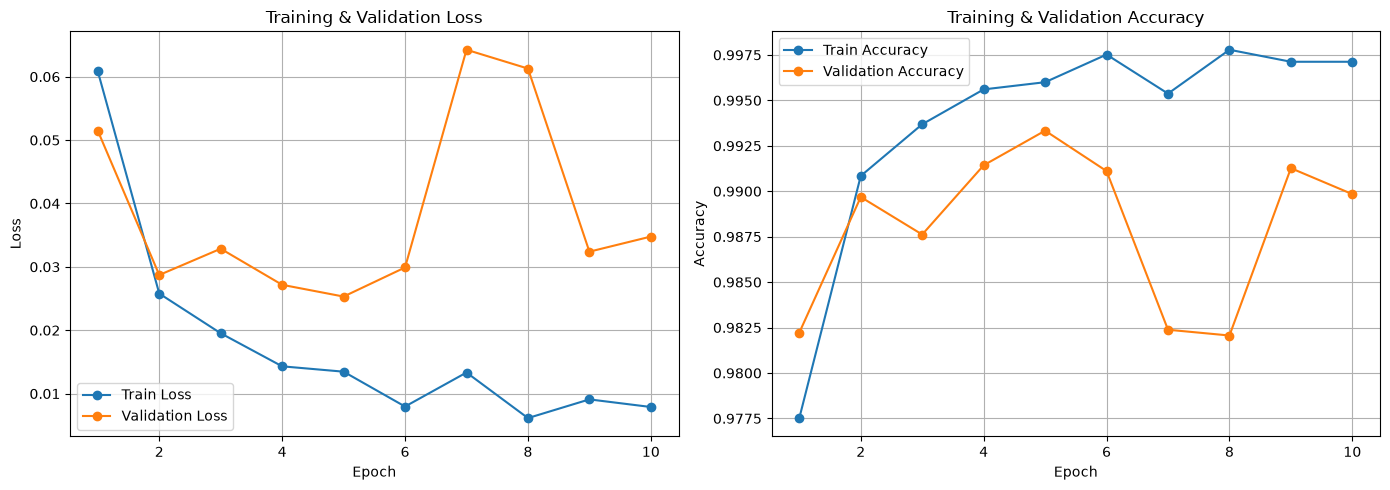

{'train_loss': [0.06084900300586519,
  0.025784850084238246,
  0.019522252928784064,
  0.01430622034441595,
  0.01346099013360679,
  0.007962034069153448,
  0.013329842266686789,
  0.006140110964527015,
  0.00908987208275237,
  0.007887605700788052],
 'train_acc': [0.9775206611570247,
  0.9908429752066116,
  0.9936859504132232,
  0.995603305785124,
  0.996,
  0.9975206611570248,
  0.9953719008264463,
  0.9977851239669422,
  0.9971239669421488,
  0.9971239669421488],
 'valid_loss': [0.05146582712116626,
  0.0287156562202417,
  0.032859437624743255,
  0.027166633071264663,
  0.025312153759115885,
  0.0299046056826705,
  0.06425391505349187,
  0.0612857649915289,
  0.03239533946047174,
  0.034778669012390774],
 'valid_acc': [0.9822222222222222,
  0.9896825396825397,
  0.9876190476190476,
  0.9914285714285714,
  0.9933333333333333,
  0.9911111111111112,
  0.9823809523809524,
  0.9820634920634921,
  0.9912698412698413,
  0.9898412698412699]}

In [44]:
# Train the model
train_model(model, criterion, optimizer, train_dataloader, valid_dataloader, num_epochs=10)